In [1]:

# 1. Library untuk pengolahan data
import pandas as pd
import numpy as np

# 2. Library untuk visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

# 3. Library untuk preprocessing
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# 4. Library untuk klasifikasi
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

# 5. Library untuk clustering
from sklearn.cluster import KMeans

# 6. Library untuk evaluasi
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    classification_report,
    silhouette_score
)

print("Semua library berhasil dipanggil!")


Semua library berhasil dipanggil!


In [4]:

import pandas as pd

# Memasukkan alamat dataset
url = "https://raw.githubusercontent.com/isnanmulia/lecture-datasets/main/heart_modified.csv"

# Membaca dataset
df = pd.read_csv(url)

# Menampilkan 5 baris pertama
display(df.head())


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140.0,289.0,0,Normal,172.0,N,0.0,Up,0
1,49,F,NAP,160.0,NaN,0,Normal,156.0,N,1.0,Flat,1
2,37,M,ATA,130.0,283.0,0,ST,98.0,N,0.0,Up,0
3,48,F,ASY,138.0,214.0,0,Normal,108.0,Y,1.5,Flat,1
4,54,M,NAP,150.0,195.0,0,Normal,122.0,N,0.0,Up,0


In [5]:
# Melihat jumlah baris dan kolom
print("Ukuran Dataset:", df.shape)

# Melihat informasi dataset
df.info()

# Memeriksa data kosong
print("\nJumlah Data Kosong:")
print(df.isnull().sum())

Ukuran Dataset: (918, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       900 non-null    float64
 4   Cholesterol     900 non-null    float64
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           900 non-null    float64
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(4), int64(3), object(5)
memory usage: 86.2+ KB

Jumlah Data Kosong:
Age                0
Sex                0
ChestPainType      0
RestingBP         18
Cholesterol       18
FastingBS          0
RestingECG         0
MaxHR   

# **SOAL NO 1**

In [6]:

# Menampilkan ukuran dataset
print("Ukuran Dataset:")
print(df.shape)

# Menampilkan nama kolom
print("\nNama Atribut:")
print(df.columns.tolist())

# Menampilkan jenis data
print("\nTipe Data:")
print(df.dtypes)

# Menghitung jumlah nilai unik
print("\nJumlah Nilai Unik:")
print(df.nunique())


Ukuran Dataset:
(918, 12)

Nama Atribut:
['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS', 'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope', 'HeartDisease']

Tipe Data:
Age                 int64
Sex                object
ChestPainType      object
RestingBP         float64
Cholesterol       float64
FastingBS           int64
RestingECG         object
MaxHR             float64
ExerciseAngina     object
Oldpeak           float64
ST_Slope           object
HeartDisease        int64
dtype: object

Jumlah Nilai Unik:
Age                50
Sex                 2
ChestPainType       4
RestingBP          67
Cholesterol       219
FastingBS           2
RestingECG          3
MaxHR             119
ExerciseAngina      2
Oldpeak            53
ST_Slope            3
HeartDisease        2
dtype: int64


In [7]:

for kolom in df.columns:
    print("\nAtribut:", kolom)
    print("Nilai unik:")
    print(df[kolom].dropna().unique())
    print("Jumlah nilai unik:", df[kolom].nunique())



Atribut: Age
Nilai unik:
[40 49 37 48 54 39 45 58 42 38 43 60 36 44 53 52 51 56 41 32 65 35 59 50
 47 31 46 57 55 63 66 34 33 61 29 62 28 30 74 68 72 64 69 67 73 70 77 75
 76 71]
Jumlah nilai unik: 50

Atribut: Sex
Nilai unik:
['M' 'F']
Jumlah nilai unik: 2

Atribut: ChestPainType
Nilai unik:
['ATA' 'NAP' 'ASY' 'TA']
Jumlah nilai unik: 4

Atribut: RestingBP
Nilai unik:
[140. 160. 130. 138. 150. 120. 110. 136. 115. 100. 124. 113. 125. 145.
 112. 132. 118. 170. 142. 190. 135. 180. 108. 155. 128. 106.  92. 200.
 122.  98. 105. 133.  95.  80. 137. 185. 165. 126. 152. 116.   0. 144.
 154. 134. 104. 139. 131. 141. 178. 146. 158. 123. 102.  96. 143. 172.
 156. 114. 127. 101. 174.  94. 148. 117. 192. 129. 164.]
Jumlah nilai unik: 67

Atribut: Cholesterol
Nilai unik:
[289. 283. 214. 195. 339. 237. 208. 207. 284. 211. 164. 204. 234. 273.
 196. 201. 248. 267. 223. 184. 288. 215. 209. 260. 468. 188. 518. 167.
 224. 172. 186. 254. 306. 250. 177. 227. 230. 294. 264. 259. 175. 318.
 216. 340. 233. 2

# **SOAL NO 2**

In [8]:

# Memeriksa jumlah data kosong
print("Jumlah Missing Values Setiap Atribut:")
print(df.isnull().sum())

# Menghitung total data kosong
print("\nTotal Missing Values:")
print(df.isnull().sum().sum())


Jumlah Missing Values Setiap Atribut:
Age                0
Sex                0
ChestPainType      0
RestingBP         18
Cholesterol       18
FastingBS          0
RestingECG         0
MaxHR             18
ExerciseAngina     0
Oldpeak            0
ST_Slope           0
HeartDisease       0
dtype: int64

Total Missing Values:
54


In [9]:

# Statistik deskriptif sebelum preprocessing
print("Statistik Deskriptif Sebelum Preprocessing:")

display(df.describe())


Statistik Deskriptif Sebelum Preprocessing:


,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,900.000000,900.000000,918.000000,900.000000,918.000000,918.000000
mean,53.510893,132.411111,199.252222,0.233115,136.874444,0.887364,0.553377
std,9.432617,18.611534,109.644221,0.423046,25.557038,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.750000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.250000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


In [10]:

# Memisahkan atribut prediktor (X) dan label (y)

X = df.drop(columns=['HeartDisease'])
y = df['HeartDisease']

# Menampilkan ukuran X dan y
print("Ukuran X:", X.shape)
print("Ukuran y:", y.shape)

print("\nAtribut Prediktor:")
print(X.columns.tolist())

print("\nAtribut Label:")
print(y.name)


Ukuran X: (918, 11)
Ukuran y: (918,)

Atribut Prediktor:
['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS', 'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope']

Atribut Label:
HeartDisease


In [11]:

# Memisahkan atribut numerik dan kategorik

numerical_cols = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_cols = X.select_dtypes(
    include=['object']
).columns.tolist()

print("Atribut Numerik:")
print(numerical_cols)

print("\nAtribut Kategorik:")
print(categorical_cols)


Atribut Numerik:
['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak']

Atribut Kategorik:
['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']


In [12]:

numerical_cols = [
    'Age',
    'RestingBP',
    'Cholesterol',
    'MaxHR',
    'Oldpeak'
]

categorical_cols = [
    'Sex',
    'ChestPainType',
    'FastingBS',
    'RestingECG',
    'ExerciseAngina',
    'ST_Slope'
]

print("Numerik:", numerical_cols)
print("Kategorik:", categorical_cols)


Numerik: ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']
Kategorik: ['Sex', 'ChestPainType', 'FastingBS', 'RestingECG', 'ExerciseAngina', 'ST_Slope']


In [13]:

from sklearn.impute import SimpleImputer

# Mengisi missing values pada atribut numerik
imputer_num = SimpleImputer(strategy='mean')

X[numerical_cols] = imputer_num.fit_transform(
    X[numerical_cols]
)

# Mengisi missing values pada atribut kategorik
imputer_cat = SimpleImputer(strategy='most_frequent')

X[categorical_cols] = imputer_cat.fit_transform(
    X[categorical_cols]
)

# Memeriksa kembali missing values
print("Missing Values Setelah Imputasi:")
print(X.isnull().sum())

print("\nTotal Missing Values:")
print(X.isnull().sum().sum())


Missing Values Setelah Imputasi:
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
dtype: int64

Total Missing Values:
0


In [14]:
from sklearn.preprocessing import StandardScaler

# Mengubah kolom kategorik menjadi angka
X_encoded = pd.get_dummies(
    X,
    columns=categorical_cols,
    dtype=int
)

# Menstandarkan kolom numerik
scaler = StandardScaler()

X_encoded[numerical_cols] = scaler.fit_transform(
    X_encoded[numerical_cols]
)

# Menampilkan hasil
print("Ukuran data setelah preprocessing:")
print(X_encoded.shape)

print("\nStatistik deskriptif setelah StandardScaler:")
print(X_encoded[numerical_cols].describe())

Ukuran data setelah preprocessing:
(918, 21)

Statistik deskriptif setelah StandardScaler:
                Age     RestingBP   Cholesterol         MaxHR       Oldpeak
count  9.180000e+02  9.180000e+02  9.180000e+02  9.180000e+02  9.180000e+02
mean  -1.083616e-16  7.275710e-16 -3.096047e-17 -7.894919e-16  1.238419e-16
std    1.000545e+00  1.000545e+00  1.000545e+00  1.000545e+00  1.000545e+00
min   -2.706015e+00 -7.189253e+00 -1.836365e+00 -3.039576e+00 -3.271482e+00
25%   -6.906294e-01 -6.738605e-01 -2.189072e-01 -6.672068e-01 -8.324324e-01
50%    5.188098e-02 -1.309111e-01  2.096499e-01  2.473414e-02 -2.695748e-01
75%    6.883185e-01  4.120382e-01  6.220785e-01  7.166751e-01  5.747115e-01
max    2.491558e+00  3.669734e+00  3.721053e+00  2.575031e+00  4.983762e+00


# **SOAL NO 3**

In [15]:
from sklearn.model_selection import train_test_split

# Menentukan data predictor hasil preprocessing
X_processed = X_encoded

# Membagi data 85% training dan 15% testing
X_train, X_test, y_train, y_test = train_test_split(
    X_processed,
    y,
    test_size=0.15,
    random_state=42,
    stratify=y
)

# Melihat ukuran data
print("Jumlah data training:", X_train.shape)
print("Jumlah data testing:", X_test.shape)

Jumlah data training: (780, 21)
Jumlah data testing: (138, 21)


In [16]:
from sklearn.ensemble import RandomForestClassifier

# Membuat model Random Forest
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Melatih model menggunakan data training
model.fit(X_train, y_train)

print("Model Random Forest berhasil dilatih!")

Model Random Forest berhasil dilatih!


In [17]:
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

# Melakukan prediksi pada data testing
y_pred = model.predict(X_test)

# Menghitung confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Menghitung accuracy
accuracy = accuracy_score(y_test, y_pred)

# Menampilkan hasil
print("Confusion Matrix:")
print(cm)

print("\nAccuracy:")
print(accuracy)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Confusion Matrix:
[[54  8]
 [ 7 69]]

Accuracy:
0.8913043478260869

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.87      0.88        62
           1       0.90      0.91      0.90        76

    accuracy                           0.89       138
   macro avg       0.89      0.89      0.89       138
weighted avg       0.89      0.89      0.89       138



# **SOAL NO 4**

In [18]:
from sklearn.cluster import KMeans

# Membuat model K-Means
kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

# Melakukan clustering
cluster_labels = kmeans.fit_predict(X_processed)

print("Clustering berhasil dilakukan!")

Clustering berhasil dilakukan!


In [19]:
from sklearn.metrics import silhouette_score

# Menghitung SSE
sse = kmeans.inertia_

# Menghitung Silhouette Score
sil_score = silhouette_score(X_processed, cluster_labels)

# Menampilkan hasil
print("SSE:", sse)
print("Silhouette Score:", sil_score)

SSE: 5875.484795288866
Silhouette Score: 0.18003858357768207


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


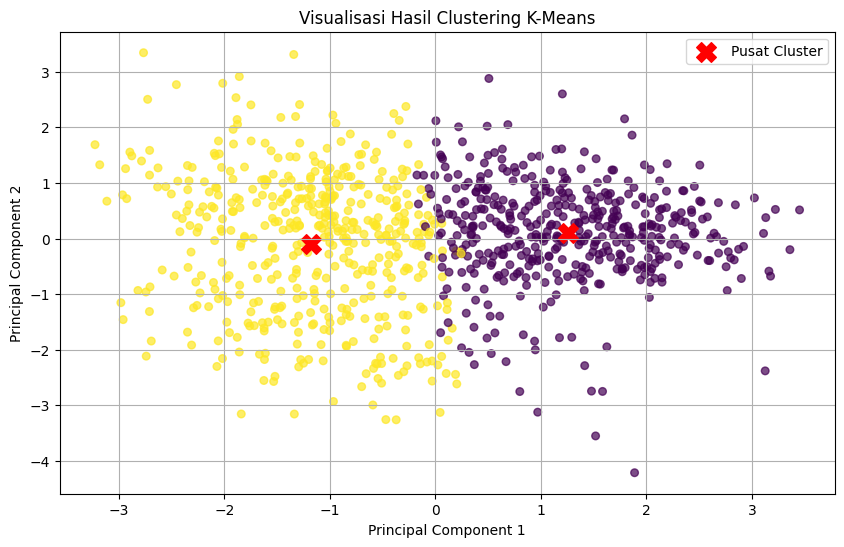

In [20]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Mengubah data menjadi 2 dimensi
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_processed)

# Mengubah posisi pusat cluster ke 2 dimensi
centers_pca = pca.transform(kmeans.cluster_centers_)

# Membuat visualisasi
plt.figure(figsize=(10, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=cluster_labels,
    cmap='viridis',
    s=30,
    alpha=0.7
)

# Menampilkan pusat cluster
plt.scatter(
    centers_pca[:, 0],
    centers_pca[:, 1],
    marker='X',
    s=200,
    c='red',
    label='Pusat Cluster'
)

plt.title('Visualisasi Hasil Clustering K-Means')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend()
plt.grid(True)

plt.show()